# Retail Sales Data Analysis

## 03 - Exploratory Data Analysis (EDA)

This notebook focuses on exploring business
performance through sales, profit, customer
segments, product categories, and time trends.

In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset

df = pd.read_csv(
    "../data/processed/superstore_cleaned.csv",
    parse_dates=["Order Date", "Ship Date"],
    dtype={"Postal Code": "string"}
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (9994, 21)


In [2]:
# Check dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   string        
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [3]:
# Preview cleaned dataset

display(df.head())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 1. Product Performance Analysis

Analyze sales and profitability across different
product categories.

Objectives:
- Compare total sales by category.
- Compare total profit by category.
- Identify the most profitable category.

In [4]:
# Analyze sales and profit by category

category_analysis = df.groupby("Category").agg(
    total_sales=("Sales", "sum"),
    total_profit=("Profit", "sum"),
    total_quantity=("Quantity", "sum"),
    total_records=("Row ID", "count")
)

# Calculate profit margin

category_analysis["profit_margin"] = (
    category_analysis["total_profit"]
    / category_analysis["total_sales"] * 100
)

# Sort by total sales

category_analysis = category_analysis.sort_values(
    by="total_sales",
    ascending=False
)

display(category_analysis.round(2))

,total_sales,total_profit,total_quantity,total_records,profit_margin
Category,,,,,
Technology,836154.03,145454.95,6939,1847,17.40
Furniture,741999.80,18451.27,8028,2121,2.49
Office Supplies,719047.03,122490.80,22906,6026,17.04


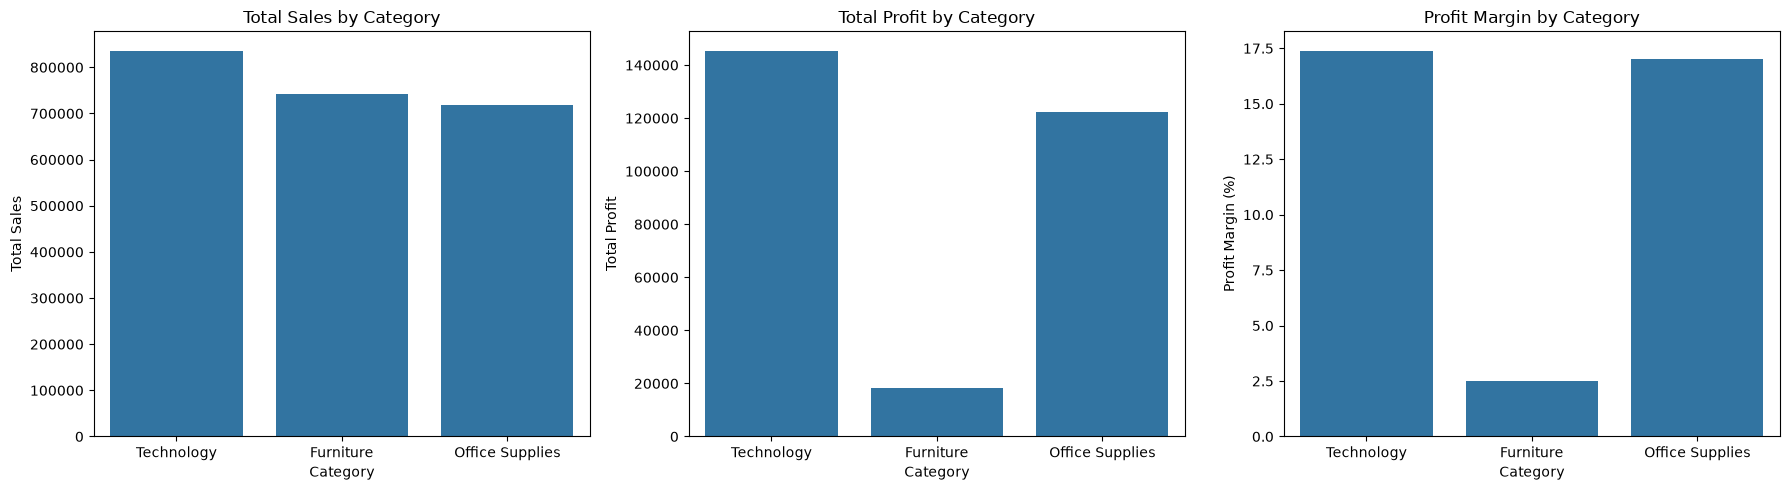

In [5]:
# Prepare data for visualization

category_plot = category_analysis.reset_index()

# Create three separate charts

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Total Sales
sns.barplot(
    data=category_plot,
    x="Category",
    y="total_sales",
    ax=axes[0]
)
axes[0].set_title("Total Sales by Category")
axes[0].set_ylabel("Total Sales")

# Total Profit
sns.barplot(
    data=category_plot,
    x="Category",
    y="total_profit",
    ax=axes[1]
)
axes[1].set_title("Total Profit by Category")
axes[1].set_ylabel("Total Profit")

# Profit Margin
sns.barplot(
    data=category_plot,
    x="Category",
    y="profit_margin",
    ax=axes[2]
)
axes[2].set_title("Profit Margin by Category")

axes[2].set_ylabel("Profit Margin (%)")

plt.tight_layout()

plt.savefig(
    "../reports/figures/01_category_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 2. Sub-Category Performance Analysis

Analyze sales and profitability across individual
product sub-categories.

Objectives:
- Identify the most profitable sub-categories.
- Identify sub-categories with negative total profit.
- Compare sales and profit margins.

In [6]:
# Analyze sales and profit by sub-category

subcategory_performance = df.groupby(
    ["Category", "Sub-Category"]
).agg(
    total_sales=("Sales", "sum"),
    total_profit=("Profit", "sum"),
    total_records=("Row ID", "count")
)

# Calculate profit margin

subcategory_performance["profit_margin"] = (
    subcategory_performance["total_profit"]
    / subcategory_performance["total_sales"] * 100
)

# Sort by total profit

subcategory_performance = subcategory_performance.sort_values(
    by="total_profit",
    ascending=True
)

display(subcategory_performance.round(2))

total_sales  total_profit  total_records  \
Category        Sub-Category                                             
Furniture       Tables          206965.53     -17725.48            319   
                Bookcases       114880.00      -3472.56            228   
Office Supplies Supplies         46673.54      -1189.10            190   
                Fasteners         3024.28        949.52            217   
Technology      Machines        189238.63       3384.76            115   
Office Supplies Labels           12486.31       5546.25            364   
                Art              27118.79       6527.79            796   
                Envelopes        16476.40       6964.18            254   
Furniture       Furnishings      91705.16      13059.14            957   
Office Supplies Appliances      107532.16      18138.01            466   
                Storage         223843.61      21278.83            846   
Furniture       Chairs          328449.10      26590.17            617   
Office Supplies Binders         203412.73      30221.76           1523   
                Paper            78479.21      34053.57           1370   
Technology      Accessories     167380.32      41936.64            775   
                Phones          330007.05      44515.73            889   
                Copiers         149528.03      55617.82             68   

                              profit_margin  
Category        Sub-Category                 
Furniture       Tables                -8.56  
                Bookcases             -3.02  
Office Supplies Supplies              -2.55  
                Fasteners             31.40  
Technology      Machines               1.79  
Office Supplies Labels                44.42  
                Art                   24.07  
                Envelopes             42.27  
Furniture       Furnishings           14.24  
Office Supplies Appliances            16.87  
                Storage                9.51  
Furniture       Chairs                 8.10  
Office Supplies Binders               14.86  
                Paper                 43.39  
Technology      Accessories           25.05  
                Phones                13.49  
                Copiers               37.20

### Sub-Category Profitability Visualization

Visualize total profit across product sub-categories
to identify profitable and loss-making areas.

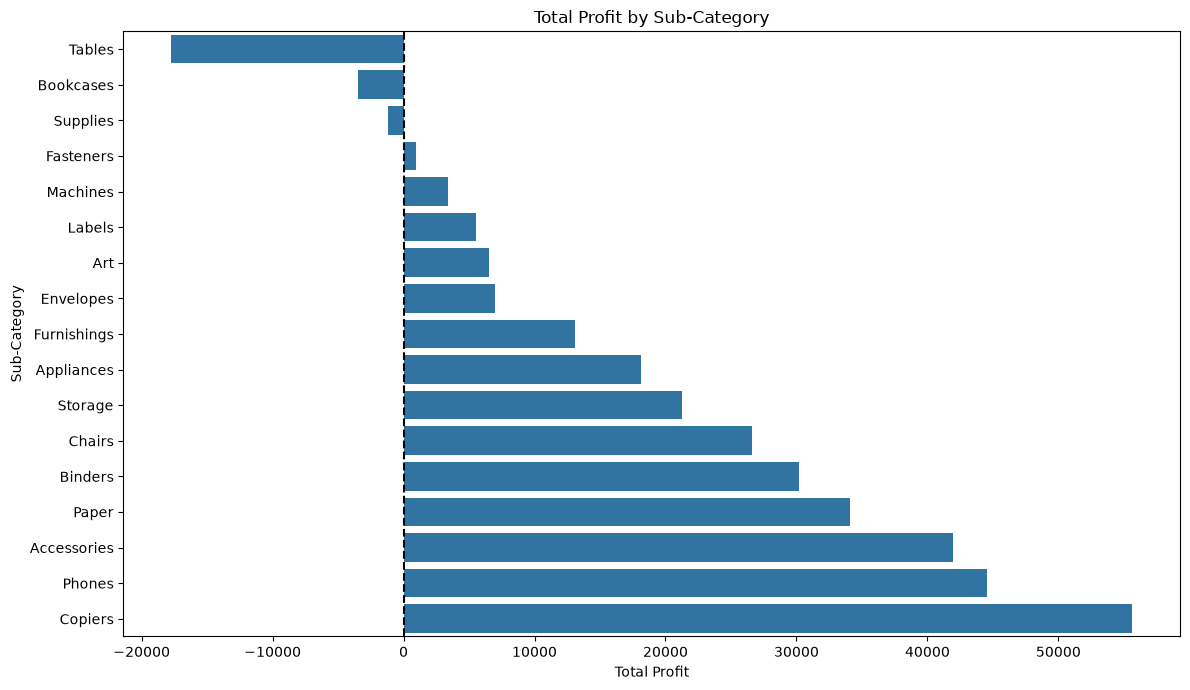

In [7]:

# Visualize profit by sub-category

subcategory_plot = (
    subcategory_performance
    .reset_index()
    .sort_values("total_profit", ascending=True)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=subcategory_plot,
    x="total_profit",
    y="Sub-Category"
)

plt.title("Total Profit by Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")

plt.axvline(x=0, color="black", linestyle="--")

plt.tight_layout()

plt.savefig(
    "../reports/figures/02_subcategory_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 3. Loss-Making Sub-Categories

Identify product sub-categories with negative
overall profit despite their parent categories
having positive total profit.

In [8]:
# Filter sub-categories with negative total profit

loss_subcategories = subcategory_performance[
    subcategory_performance["total_profit"] < 0
]

display(loss_subcategories.round(2))

total_sales  total_profit  total_records  \
Category        Sub-Category                                             
Furniture       Tables          206965.53     -17725.48            319   
                Bookcases       114880.00      -3472.56            228   
Office Supplies Supplies         46673.54      -1189.10            190   

                              profit_margin  
Category        Sub-Category                 
Furniture       Tables                -8.56  
                Bookcases             -3.02  
Office Supplies Supplies              -2.55

In [9]:
# Calculate total profit by parent category

parent_profit = df.groupby("Category")["Profit"].sum()

# Calculate total profit from loss-making sub-categories

loss_by_category = loss_subcategories.groupby(
    level="Category"
)["total_profit"].sum()

# Compare parent categories and loss-making sub-categories

profit_comparison = pd.DataFrame({
    "category_total_profit": parent_profit,
    "loss_subcategory_profit": loss_by_category
})

profit_comparison["loss_subcategory_profit"] = (
    profit_comparison["loss_subcategory_profit"].fillna(0)
)

profit_comparison["other_subcategories_net_profit"] = (
    profit_comparison["category_total_profit"]
    - profit_comparison["loss_subcategory_profit"]
)

display(profit_comparison.round(2))

,category_total_profit,loss_subcategory_profit,other_subcategories_net_profit
Category,,,
Furniture,18451.27,-21198.04,39649.31
Office Supplies,122490.80,-1189.10,123679.90
Technology,145454.95,0.00,145454.95


## 4. Product-Level Profitability Analysis

Investigate individual product profitability
to identify products contributing to losses.

Objectives:
- Identify products with negative total profit.
- Rank products based on total profit.
- Identify products with the largest financial losses.

In [10]:
# Analyze profit by individual product

product_performance = df.groupby(
    ["Category", "Sub-Category", "Product Name"]
).agg(
    total_sales=("Sales", "sum"),
    total_profit=("Profit", "sum"),
    total_quantity=("Quantity", "sum"),
    total_records=("Row ID", "count")
)

# Calculate profit margin

product_performance["profit_margin"] = (
    product_performance["total_profit"]
    / product_performance["total_sales"] * 100
)

# Sort products by total profit

product_performance = product_performance.sort_values(
    by="total_profit",
    ascending=True
)

display(product_performance.head(15).round(2))

total_sales  \
Category        Sub-Category Product Name                                                      
Technology      Machines     Cubify CubeX 3D Printer Double Head Print              11099.96   
                             Lexmark MX611dhe Monochrome Laser Printer              16829.90   
                             Cubify CubeX 3D Printer Triple Head Print               7999.98   
Furniture       Tables       Chromcraft Bull-Nose Wood Oval Conference Table...      9917.64   
                             Bush Advantage Collection Racetrack Conference ...      9544.72   
Office Supplies Binders      GBC DocuBind P400 Electric Binding System              17965.07   
Technology      Machines     Cisco TelePresence System EX90 Videoconferencin...     22638.48   
Office Supplies Supplies     Martin Yale Chadless Opener Electric Letter Opener     16656.20   
Furniture       Tables       Balt Solid Wood Round Tables                            6518.75   
                             BoxOffice By Design Rectangular and Half-Moon M...      1706.25   
                             Riverside Furniture Oval Coffee Table, Oval End...      4446.18   
Technology      Machines     Epson TM-T88V Direct Thermal Printer - Monochro...      1212.70   
Furniture       Chairs       Hon 2090 “Pillow Soft” Series Mid Back Swivel/T...      5282.42   
                Bookcases    O'Sullivan 4-Shelf Bookcase in Odessa Pine              2740.20   
                Tables       Bretford “Just In Time” Height-Adjustable Multi...      5634.90   

                                                                                 total_profit  \
Category        Sub-Category Product Name                                                       
Technology      Machines     Cubify CubeX 3D Printer Double Head Print               -8879.97   
                             Lexmark MX611dhe Monochrome Laser Printer               -4589.97   
                             Cubify CubeX 3D Printer Triple Head Print               -3839.99   
Furniture       Tables       Chromcraft Bull-Nose Wood Oval Conference Table...      -2876.12   
                             Bush Advantage Collection Racetrack Conference ...      -1934.40   
Office Supplies Binders      GBC DocuBind P400 Electric Binding System               -1878.17   
Technology      Machines     Cisco TelePresence System EX90 Videoconferencin...      -1811.08   
Office Supplies Supplies     Martin Yale Chadless Opener Electric Letter Opener      -1299.18   
Furniture       Tables       Balt Solid Wood Round Tables                            -1201.06   
                             BoxOffice By Design Rectangular and Half-Moon M...      -1148.44   
                             Riverside Furniture Oval Coffee Table, Oval End...      -1147.40   
Technology      Machines     Epson TM-T88V Direct Thermal Printer - Monochro...      -1057.23   
Furniture       Chairs       Hon 2090 “Pillow Soft” Series Mid Back Swivel/T...       -989.05   
                Bookcases    O'Sullivan 4-Shelf Bookcase in Odessa Pine               -975.10   
                Tables       Bretford “Just In Time” Height-Adjustable Multi...       -964.19   

                                                                                 total_quantity  \
Category        Sub-Category Product Name                                                         
Technology      Machines     Cubify CubeX 3D Printer Double Head Print                        9   
                             Lexmark MX611dhe Monochrome Laser Printer                       18   
                             Cubify CubeX 3D Printer Triple Head Print                        4   
Furniture       Tables       Chromcraft Bull-Nose Wood Oval Conference Table...              27   
                             Bush Advantage Collection Racetrack Conference ...              33   
Office Supplies Binders      GBC DocuBind P400 Electric Binding System                       27   
Techno

## 5. Loss-Making Product Analysis

Analyze the number and proportion of products
with negative total profit across sub-categories.

The objective is to identify where loss-making
products are concentrated.

In [11]:
# Convert product analysis into a regular DataFrame

product_summary = product_performance.reset_index()

# Identify loss-making products

product_summary["is_loss_making"] = (
    product_summary["total_profit"] < 0
)

# Calculate negative profit contribution

product_summary["loss_contribution"] = (
    product_summary["total_profit"].where(
        product_summary["total_profit"] < 0,
        0
    )
)

# Aggregate product performance by sub-category

loss_product_summary = product_summary.groupby(
    ["Category", "Sub-Category"]
).agg(
    total_products=("Product Name", "nunique"),
    loss_making_products=("is_loss_making", "sum"),
    combined_losses=("loss_contribution", "sum"),
    net_profit=("total_profit", "sum")
)

# Calculate percentage of loss-making products

loss_product_summary["loss_product_percentage"] = (
    loss_product_summary["loss_making_products"]
    / loss_product_summary["total_products"] * 100
)

# Sort by number of loss-making products

loss_product_summary = loss_product_summary.sort_values(
    by="loss_making_products",
    ascending=False
)

display(loss_product_summary.round(2))

total_products  loss_making_products  \
Category        Sub-Category                                         
Office Supplies Binders                  211                    50   
Furniture       Tables                    56                    42   
Office Supplies Storage                  132                    39   
Furniture       Bookcases                 50                    33   
Technology      Phones                   189                    26   
Furniture       Furnishings              186                    24   
                Chairs                    88                    24   
Technology      Machines                  63                    23   
Office Supplies Appliances                97                    15   
                Supplies                  36                    11   
Technology      Accessories              147                     7   
Office Supplies Fasteners                 34                     7   
                Art                      157                     0   
                Envelopes                 44                     0   
                Paper                    277                     0   
                Labels                    70                     0   
Technology      Copiers                   13                     0   

                              combined_losses  net_profit  \
Category        Sub-Category                                
Office Supplies Binders              -4318.95    30221.76   
Furniture       Tables              -21492.48   -17725.48   
Office Supplies Storage              -4411.11    21278.83   
Furniture       Bookcases            -7032.70    -3472.56   
Technology      Phones               -1773.05    44515.73   
Furniture       Furnishings          -3038.05    13059.14   
                Chairs               -5498.51    26590.17   
Technology      Machines            -25405.37     3384.76   
Office Supplies Appliances           -1798.67    18138.01   
                Supplies             -2098.34    -1189.10   
Technology      Accessories           -174.62    41936.64   
Office Supplies Fasteners              -26.54      949.52   
                Art                      0.00     6527.79   
                Envelopes                0.00     6964.18   
                Paper                    0.00    34053.57   
                Labels                   0.00     5546.25   
Technology      Copiers                  0.00    55617.82   

                              loss_product_percentage  
Category        Sub-Category                           
Office Supplies Binders                         23.70  
Furniture       Tables                          75.00  
Office Supplies Storage                         29.55  
Furniture       Bookcases                       66.00  
Technology      Phones                          13.76  
Furniture       Furnishings                     12.90  
                Chairs                          27.27  
Technology      Machines                        36.51  
Office Supplies Appliances                      15.46  
                Supplies                        30.56  
Technology      Accessories                      4.76  
Office Supplies Fasteners                       20.59  
                Art                              0.00  
                Envelopes                        0.00  
                Paper                            0.00  
                Labels                           0.00  
Technology      Copiers                          0.00

## 6. Regional Performance Analysis

Analyze sales and profitability across different
geographical regions.

Objectives:
- Compare total sales by region.
- Compare total profit by region.
- Identify the most profitable region.
- Evaluate regional profit margins.

In [12]:
# Analyze sales and profit by region

region_analysis = df.groupby("Region").agg(
    total_sales=("Sales", "sum"),
    total_profit=("Profit", "sum"),
    total_quantity=("Quantity", "sum"),
    total_records=("Row ID", "count")
)

# Calculate profit margin

region_analysis["profit_margin"] = (
    region_analysis["total_profit"]
    / region_analysis["total_sales"] * 100
)

# Sort by total profit

region_analysis = region_analysis.sort_values(
    by="total_profit",
    ascending=False
)

display(region_analysis.round(2))

,total_sales,total_profit,total_quantity,total_records,profit_margin
Region,,,,,
West,725457.82,108418.45,12266,3203,14.94
East,678781.24,91522.78,10618,2848,13.48
South,391721.90,46749.43,6209,1620,11.93
Central,501239.89,39706.36,8780,2323,7.92


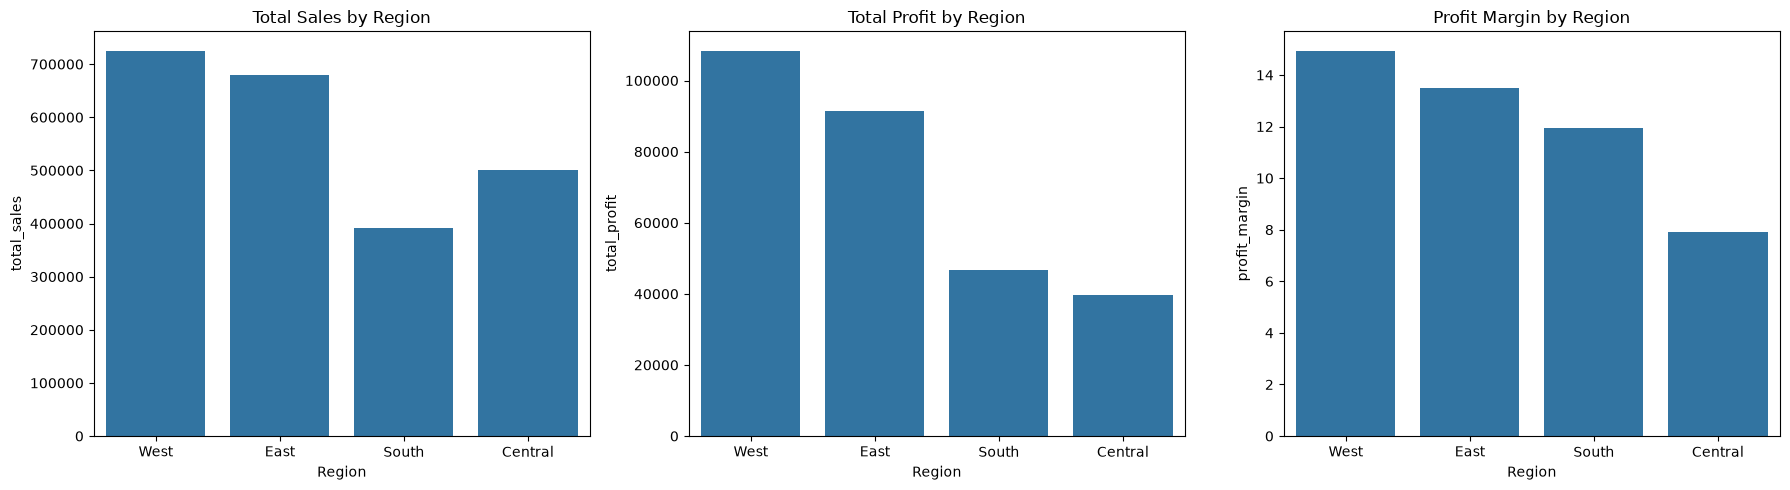

In [13]:
# Prepare regional data

region_plot = region_analysis.reset_index()

# Create visualizations

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Total Sales
sns.barplot(
    data=region_plot,
    x="Region",
    y="total_sales",
    ax=axes[0]
)
axes[0].set_title("Total Sales by Region")

# Total Profit
sns.barplot(
    data=region_plot,
    x="Region",
    y="total_profit",
    ax=axes[1]
)
axes[1].set_title("Total Profit by Region")

# Profit Margin
sns.barplot(
    data=region_plot,
    x="Region",
    y="profit_margin",
    ax=axes[2]
)
axes[2].set_title("Profit Margin by Region")


plt.tight_layout()

plt.savefig(
    "../reports/figures/03_regional_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Regional Category Performance

Analyze sales and profitability across product
categories within each geographical region.

Objectives:
- Compare category performance across regions.
- Identify categories with low profitability.
- Investigate the low profit margin in Central.

In [14]:
# Analyze performance by region and category

regional_category_analysis = df.groupby(
    ["Region", "Category"]
).agg(
    total_sales=("Sales", "sum"),
    total_profit=("Profit", "sum"),
    total_records=("Row ID", "count")
)

# Calculate profit margin

regional_category_analysis["profit_margin"] = (
    regional_category_analysis["total_profit"]
    / regional_category_analysis["total_sales"] * 100
)

display(regional_category_analysis.round(2))

total_sales  total_profit  total_records  \
Region  Category                                                    
Central Furniture          163797.16      -2871.05            481   
        Office Supplies    167026.42       8879.98           1422   
        Technology         170416.31      33697.43            420   
East    Furniture          208291.20       3046.17            601   
        Office Supplies    205516.06      41014.58           1712   
        Technology         264973.98      47462.04            535   
South   Furniture          117298.68       6771.21            332   
        Office Supplies    125651.31      19986.39            995   
        Technology         148771.91      19991.83            293   
West    Furniture          252612.74      11504.95            707   
        Office Supplies    220853.25      52609.85           1897   
        Technology         251991.83      44303.65            599   

                         profit_margin  
Region  Category                        
Central Furniture                -1.75  
        Office Supplies           5.32  
        Technology               19.77  
East    Furniture                 1.46  
        Office Supplies          19.96  
        Technology               17.91  
South   Furniture                 5.77  
        Office Supplies          15.91  
        Technology               13.44  
West    Furniture                 4.55  
        Office Supplies          23.82  
        Technology               17.58

In [15]:
# Analyze category performance in Central

central_analysis = regional_category_analysis.loc["Central"]

central_analysis = central_analysis.sort_values(
    by="total_profit",
    ascending=True
)

display(central_analysis.round(2))

,total_sales,total_profit,total_records,profit_margin
Category,,,,
Furniture,163797.16,-2871.05,481,-1.75
Office Supplies,167026.42,8879.98,1422,5.32
Technology,170416.31,33697.43,420,19.77


## 8. Central Furniture Sub-Category Analysis

Investigate the profitability of Furniture
sub-categories within the Central region.

Objectives:
- Identify loss-making sub-categories.
- Compare total sales and profit.
- Identify the largest contributors to losses.

In [16]:
# Filter Central Furniture transactions

central_furniture = df[
    (df["Region"] == "Central") &
    (df["Category"] == "Furniture")
]

# Analyze performance by sub-category

central_furniture_analysis = central_furniture.groupby(
    "Sub-Category"
).agg(
    total_sales=("Sales", "sum"),
    total_profit=("Profit", "sum"),
    total_quantity=("Quantity", "sum"),
    total_records=("Row ID", "count")
)

# Calculate profit margin

central_furniture_analysis["profit_margin"] = (
    central_furniture_analysis["total_profit"]
    / central_furniture_analysis["total_sales"] * 100
)

# Sort from lowest profit to highest

central_furniture_analysis = (
    central_furniture_analysis.sort_values(
        by="total_profit",
        ascending=True
    )
)

display(central_furniture_analysis.round(2))

,total_sales,total_profit,total_quantity,total_records,profit_margin
Sub-Category,,,,,
Furnishings,15254.37,-3906.22,758,205,-25.61
Tables,39154.97,-3559.65,262,72,-9.09
Bookcases,24157.18,-1997.90,192,50,-8.27
Chairs,85230.65,6592.72,615,154,7.74


## 9. Central Furnishings Product Analysis

Investigate individual Furnishings products
in the Central region.

Objectives:
- Identify products with the lowest total profit.
- Examine transaction-level losses.
- Identify products that require further investigation.

In [17]:
# Filter Central Furnishings transactions

central_furnishings = df[
    (df["Region"] == "Central") &
    (df["Category"] == "Furniture") &
    (df["Sub-Category"] == "Furnishings")
]

# Analyze performance by individual product

furnishings_product_analysis = central_furnishings.groupby(
    ["Product ID", "Product Name"]
).agg(
    total_sales=("Sales", "sum"),
    total_profit=("Profit", "sum"),
    total_quantity=("Quantity", "sum"),
    total_records=("Row ID", "count"),
    loss_records=("Profit", lambda x: (x < 0).sum())
)

# Calculate profit margin

furnishings_product_analysis["profit_margin"] = (
    furnishings_product_analysis["total_profit"]
    / furnishings_product_analysis["total_sales"] * 100
)

# Calculate transaction loss percentage

furnishings_product_analysis["loss_percentage"] = (
    furnishings_product_analysis["loss_records"]
    / furnishings_product_analysis["total_records"] * 100
)

# Sort by total profit

furnishings_product_analysis = (
    furnishings_product_analysis.sort_values(
        by="total_profit",
        ascending=True
    )
)

display(furnishings_product_analysis.head(15).round(2))

,,total_sales,total_profit,total_quantity,total_records,loss_records,profit_margin,loss_percentage
Product ID,Product Name,,,,,,,
FUR-FU-10003806,"Tenex Chairmat w/ Average Lip, 45"" x 53""",544.90,-681.12,9,2,2,-125.00,100.00
FUR-FU-10001468,Tenex Antistatic Computer Chair Mats,341.96,-427.45,5,1,1,-125.00,100.00
FUR-FU-10003601,"Deflect-o RollaMat Studded, Beveled Mat for Medium Pile Carpeting",405.81,-426.10,11,2,2,-105.00,100.00
FUR-FU-10000576,Luxo Professional Fluorescent Magnifier Lamp with Clamp-Mount Base,419.68,-356.73,5,1,1,-85.00,100.00
FUR-FU-10002918,Eldon ClusterMat Chair Mat with Cordless Antistatic Protection,800.62,-252.01,13,3,1,-31.48,33.33
FUR-FU-10002116,"Tenex Carpeted, Granite-Look or Clear Contemporary Contour Shape Chair Mats",410.12,-247.48,10,3,2,-60.34,66.67
FUR-FU-10003394,"Tenex ""The Solids"" Textured Chair Mats",223.87,-240.66,8,2,2,-107.50,100.00
FUR-FU-10002298,"Rubbermaid ClusterMat Chairmats, Mat Size- 66"" x 60"", Lip 20"" x 11"" -90 Degree Angle",599.29,-239.72,9,2,1,-40.00,50.00
FUR-FU-10003773,Eldon Cleatmat Plus Chair Mats for High Pile Carpets,159.04,-194.82,5,1,1,-122.50,100.00


## 10. Tenex Product Investigation

Investigate the profitability of Tenex products
within Central Furnishings.

Objectives:
- Identify Tenex products with negative profit.
- Examine their average discount.
- Compare sales and profitability across products.

In [18]:
# Filter Tenex products

tenex_data = central_furnishings[
    central_furnishings["Product Name"].str.contains(
        "Tenex",
        case=False,
        na=False
    )
]

# Analyze Tenex products

tenex_analysis = tenex_data.groupby(
    ["Product ID", "Product Name"]
).agg(
    total_records=("Row ID", "count"),
    total_sales=("Sales", "sum"),
    total_profit=("Profit", "sum"),
    total_quantity=("Quantity", "sum"),
    average_discount=("Discount", "mean"),
    loss_records=("Profit", lambda x: (x < 0).sum())
)

tenex_analysis["loss_percentage"] = (
    tenex_analysis["loss_records"]
    / tenex_analysis["total_records"] * 100
)

# Sort by total profit

tenex_analysis = tenex_analysis.sort_values(
    by="total_profit",
    ascending=True
)

display(tenex_analysis.round(2))

,,total_records,total_sales,total_profit,total_quantity,average_discount,loss_records,loss_percentage
Product ID,Product Name,,,,,,,
FUR-FU-10003806,"Tenex Chairmat w/ Average Lip, 45"" x 53""",2,544.90,-681.12,9,0.6,2,100.00
FUR-FU-10001468,Tenex Antistatic Computer Chair Mats,1,341.96,-427.45,5,0.6,1,100.00
FUR-FU-10002116,"Tenex Carpeted, Granite-Look or Clear Contemporary Contour Shape Chair Mats",3,410.12,-247.48,10,0.4,2,66.67
FUR-FU-10003394,"Tenex ""The Solids"" Textured Chair Mats",2,223.87,-240.66,8,0.6,2,100.00
FUR-FU-10000193,Tenex Chairmats For Use with Hard Floors,2,103.94,-135.12,8,0.6,2,100.00
FUR-FU-10002703,"Tenex Traditional Chairmats for Hard Floors, Average Lip, 36"" x 48""",1,51.56,-61.87,2,0.6,1,100.00
FUR-FU-10003708,"Tenex Traditional Chairmats for Medium Pile Carpet, Standard Lip, 36"" x 48""",2,194.08,-45.49,5,0.3,1,50.00
FUR-FU-10000305,"Tenex V2T-RE Standard Weight Series Chair Mat, 45"" x 53"", Lip 25"" x 12""",1,212.94,34.07,3,0.0,0,0.00


In [19]:
# Analyze Tenex profitability by exact discount level

tenex_discount_analysis = tenex_data.groupby("Discount").agg(
    total_records=("Row ID", "count"),
    average_profit=("Profit", "mean"),
    total_profit=("Profit", "sum"),
    loss_records=("Profit", lambda x: (x < 0).sum())
)

tenex_discount_analysis["loss_percentage"] = (
    tenex_discount_analysis["loss_records"]
    / tenex_discount_analysis["total_records"] * 100
)

display(tenex_discount_analysis.round(2))

,total_records,average_profit,total_profit,loss_records,loss_percentage
Discount,,,,,
0.0,3,24.80,74.39,0,0.0
0.6,11,-170.87,-1879.52,11,100.0


In [20]:
# Analyze all Central Furnishings by discount level

furnishings_discount_analysis = (
    central_furnishings.groupby("Discount").agg(
        total_records=("Row ID", "count"),
        average_profit=("Profit", "mean"),
        total_profit=("Profit", "sum"),
        loss_records=("Profit", lambda x: (x < 0).sum())
    )
)

furnishings_discount_analysis["loss_percentage"] = (
    furnishings_discount_analysis["loss_records"]
    / furnishings_discount_analysis["total_records"] * 100
)

display(furnishings_discount_analysis.round(2))

,total_records,average_profit,total_profit,loss_records,loss_percentage
Discount,,,,,
0.0,67,30.42,2038.44,0,0.0
0.6,138,-43.08,-5944.66,138,100.0


### Key Findings - Central Furnishings

The analysis reveals a substantial profitability
difference across discount levels.

- At 0.0 discount, 67 records generated a total
  profit of $2,038.44.
- At 0.6 discount, 138 records generated a
  total loss of $5,944.66.
- All records at the 0.6 discount level
  resulted in negative profit.

This indicates a strong association between
the 60% discount level and negative profitability
within Central Furnishings.

Further investigation is needed to determine
whether product mix and other factors contribute
to this pattern.

## 10. Customer Segment Analysis

Analyze sales and profitability across customer
segments.

Objectives:
- Compare total sales by customer segment.
- Compare total profit and profit margins.
- Identify the most valuable customer segment.

In [21]:
# Analyze performance by customer segment

segment_analysis = df.groupby("Segment").agg(
    total_sales=("Sales", "sum"),
    total_profit=("Profit", "sum"),
    total_quantity=("Quantity", "sum"),
    total_orders=("Order ID", "nunique"),
    total_customers=("Customer ID", "nunique")
)

# Calculate profit margin

segment_analysis["profit_margin"] = (
    segment_analysis["total_profit"]
    / segment_analysis["total_sales"] * 100
)

# Sort by total sales

segment_analysis = segment_analysis.sort_values(
    by="total_sales",
    ascending=False
)

display(segment_analysis.round(2))

,total_sales,total_profit,total_quantity,total_orders,total_customers,profit_margin
Segment,,,,,,
Consumer,1161401.34,134119.21,19521,2586,409,11.55
Corporate,706146.37,91979.13,11608,1514,236,13.03
Home Office,429653.15,60298.68,6744,909,148,14.03


In [22]:
# Calculate average performance per order and customer

segment_analysis["sales_per_order"] = (
    segment_analysis["total_sales"]
    / segment_analysis["total_orders"]
)

segment_analysis["profit_per_order"] = (
    segment_analysis["total_profit"]
    / segment_analysis["total_orders"]
)

segment_analysis["sales_per_customer"] = (
    segment_analysis["total_sales"]
    / segment_analysis["total_customers"]
)

segment_analysis["profit_per_customer"] = (
    segment_analysis["total_profit"]
    / segment_analysis["total_customers"]
)

segment_analysis["orders_per_customer"] = (
    segment_analysis["total_orders"]
    / segment_analysis["total_customers"]
)

display(segment_analysis.round(2))

,total_sales,total_profit,total_quantity,total_orders,total_customers,profit_margin,sales_per_order,profit_per_order,sales_per_customer,profit_per_customer,orders_per_customer
Segment,,,,,,,,,,,
Consumer,1161401.34,134119.21,19521,2586,409,11.55,449.11,51.86,2839.61,327.92,6.32
Corporate,706146.37,91979.13,11608,1514,236,13.03,466.41,60.75,2992.15,389.74,6.42
Home Office,429653.15,60298.68,6744,909,148,14.03,472.67,66.34,2903.06,407.42,6.14


## 11. Sales Trend Analysis

Analyze sales and profitability over time.

Objectives:
- Compare annual sales performance.
- Compare annual profit performance.
- Identify growth and decline patterns.
- Examine monthly sales trends.

In [23]:
# Analyze annual sales and profit

yearly_analysis = df.groupby(
    df["Order Date"].dt.year
).agg(
    total_sales=("Sales", "sum"),
    total_profit=("Profit", "sum"),
    total_orders=("Order ID", "nunique"),
    total_quantity=("Quantity", "sum")
)

# Calculate annual profit margin

yearly_analysis["profit_margin"] = (
    yearly_analysis["total_profit"]
    / yearly_analysis["total_sales"] * 100
)

display(yearly_analysis.round(2))

,total_sales,total_profit,total_orders,total_quantity,profit_margin
Order Date,,,,,
2014,484247.50,49543.97,969,7581,10.23
2015,470532.51,61618.60,1038,7979,13.10
2016,609205.60,81795.17,1315,9837,13.43
2017,733215.26,93439.27,1687,12476,12.74


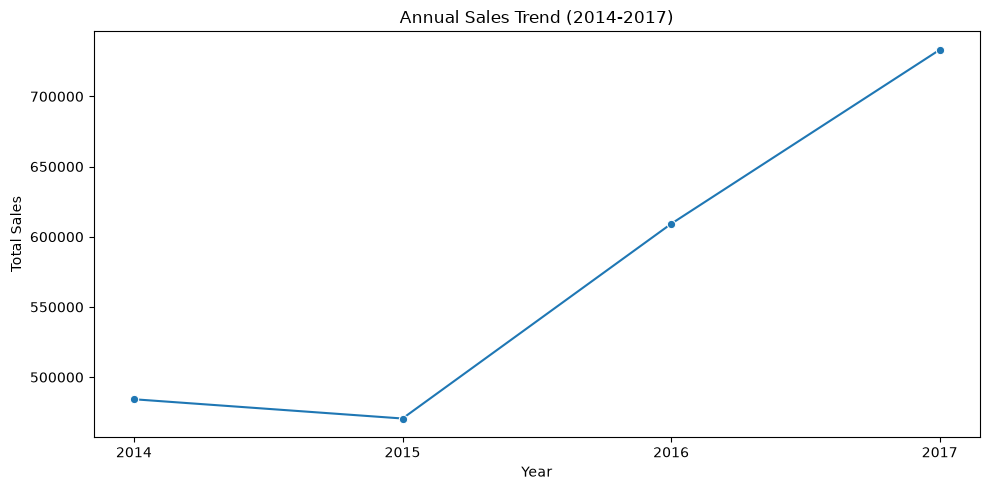

In [24]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_analysis.reset_index(),
    x="Order Date",
    y="total_sales",
    marker="o"
)

plt.title("Annual Sales Trend (2014-2017)")
plt.xlabel("Year")
plt.ylabel("Total Sales")

plt.xticks([2014, 2015, 2016, 2017])

plt.tight_layout()

plt.savefig(
    "../reports/figures/04_annual_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

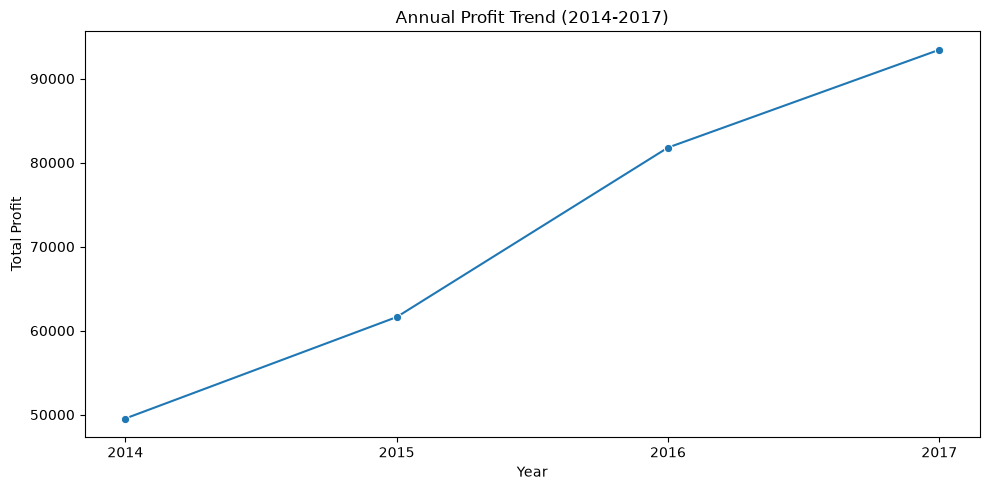

In [25]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_analysis.reset_index(),
    x="Order Date",
    y="total_profit",
    marker="o"
)

plt.title("Annual Profit Trend (2014-2017)")
plt.xlabel("Year")
plt.ylabel("Total Profit")

plt.xticks([2014, 2015, 2016, 2017])

plt.tight_layout()

plt.savefig(
    "../reports/figures/05_annual_profit_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 12. Annual Discount Analysis

Analyze annual discount patterns to investigate
whether changes in discount levels are associated
with changes in sales performance.

In [26]:
# Analyze annual discount patterns

discount_yearly = df.groupby(
    df["Order Date"].dt.year
).agg(
    average_discount=("Discount", "mean"),
    total_sales=("Sales", "sum"),
    total_profit=("Profit", "sum"),
    total_orders=("Order ID", "nunique"),
    total_quantity=("Quantity", "sum")
)

# Calculate profit margin

discount_yearly["profit_margin"] = (
    discount_yearly["total_profit"]
    / discount_yearly["total_sales"] * 100
)

# Calculate year-over-year sales growth

discount_yearly["sales_growth"] = (
    discount_yearly["total_sales"].pct_change() * 100
)

display(discount_yearly.round(2))

,average_discount,total_sales,total_profit,total_orders,total_quantity,profit_margin,sales_growth
Order Date,,,,,,,
2014,0.16,484247.50,49543.97,969,7581,10.23,NaN
2015,0.16,470532.51,61618.60,1038,7979,13.10,-2.83
2016,0.15,609205.60,81795.17,1315,9837,13.43,29.47
2017,0.16,733215.26,93439.27,1687,12476,12.74,20.36


In [27]:
# Calculate sales growth

yearly_analysis["sales_growth"] = (
    yearly_analysis["total_sales"].pct_change() * 100
)

# Calculate average sales per order

yearly_analysis["sales_per_order"] = (
    yearly_analysis["total_sales"]
    / yearly_analysis["total_orders"]
)

# Calculate average quantity per order

yearly_analysis["quantity_per_order"] = (
    yearly_analysis["total_quantity"]
    / yearly_analysis["total_orders"]
)

# Display results

display(
    yearly_analysis[
        [
            "total_sales",
            "total_orders",
            "sales_per_order",
            "quantity_per_order",
            "sales_growth"
        ]
    ].round(2)
)

,total_sales,total_orders,sales_per_order,quantity_per_order,sales_growth
Order Date,,,,,
2014,484247.50,969,499.74,7.82,NaN
2015,470532.51,1038,453.31,7.69,-2.83
2016,609205.60,1315,463.27,7.48,29.47
2017,733215.26,1687,434.63,7.40,20.36


## 13. Monthly Sales Trend

Analyze monthly sales and profit performance
from 2014 to 2017.

Objectives:
- Identify monthly sales trends.
- Observe seasonal patterns.
- Identify months with high and low sales.
- Compare monthly sales and profit.

In [28]:
# Aggregate sales and profit by month

monthly_analysis = (
    df.set_index("Order Date")
    .resample("MS")
    .agg(
        total_sales=("Sales", "sum"),
        total_profit=("Profit", "sum"),
        total_orders=("Order ID", "nunique"),
        total_quantity=("Quantity", "sum")
    )
    .reset_index()
)

# Calculate monthly profit margin

monthly_analysis["profit_margin"] = (
    monthly_analysis["total_profit"]
    / monthly_analysis["total_sales"] * 100
)

print("Total months:", len(monthly_analysis))

display(monthly_analysis.head(12).round(2))

Total months: 48


C:\Users\marko\AppData\Local\Temp\ipykernel_5260\1387288918.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_analysis.head(12).round(2))


,Order Date,total_sales,total_profit,total_orders,total_quantity,profit_margin
0,2014-01-01,14236.90,2450.19,32,284,17.21
1,2014-02-01,4519.89,862.31,28,159,19.08
2,2014-03-01,55691.01,498.73,71,585,0.90
3,2014-04-01,28295.34,3488.84,66,536,12.33
4,2014-05-01,23648.29,2738.71,69,466,11.58
5,2014-06-01,34595.13,4976.52,66,521,14.39
6,2014-07-01,33946.39,-841.48,65,550,-2.48
7,2014-08-01,27909.47,5318.10,72,609,19.05
8,2014-09-01,81777.35,8328.10,130,1000,10.18
9,2014-10-01,31453.39,3448.26,78,573,10.96


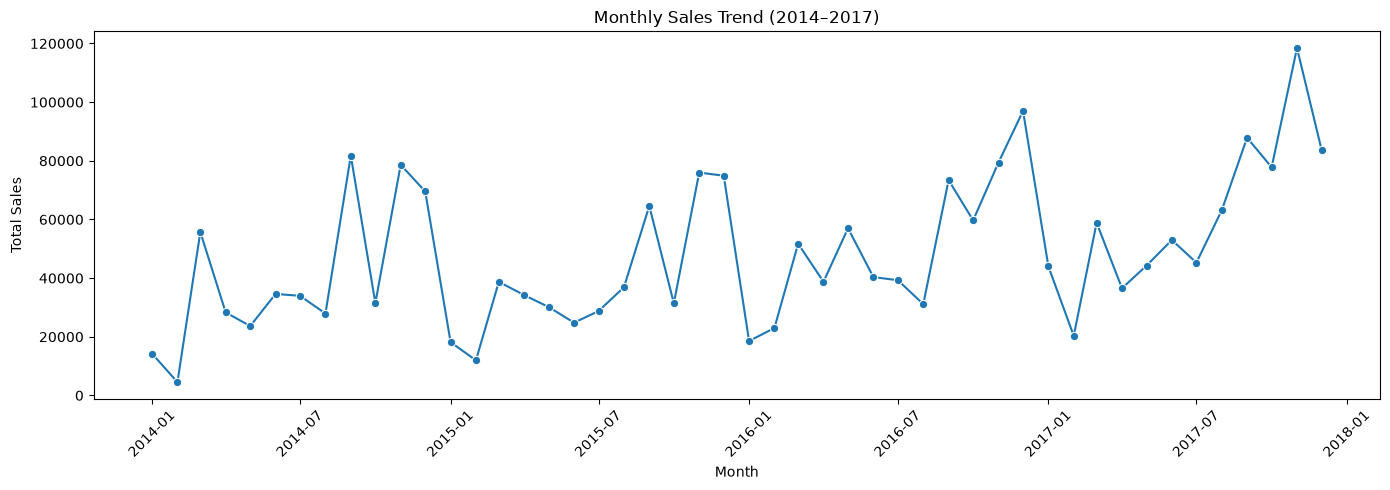

In [29]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_analysis,
    x="Order Date",
    y="total_sales",
    marker="o"
)

plt.title("Monthly Sales Trend (2014–2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../reports/figures/06_monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

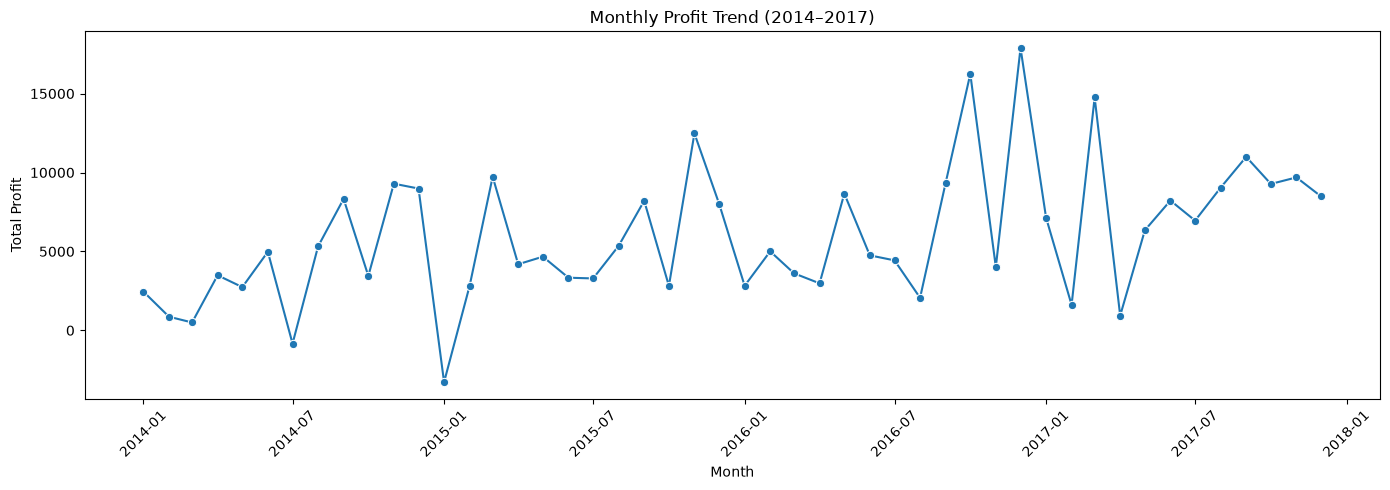

In [30]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_analysis,
    x="Order Date",
    y="total_profit",
    marker="o"
)

plt.title("Monthly Profit Trend (2014–2017)")
plt.xlabel("Month")
plt.ylabel("Total Profit")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../reports/figures/07_monthly_profit_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 14. Monthly Seasonality Analysis

Analyze average monthly sales and profit across
the four-year observation period.

Objectives:
- Identify months with higher average sales.
- Identify months with lower average sales.
- Examine recurring monthly patterns.

In [31]:
# Extract calendar month

monthly_analysis["month"] = (
    monthly_analysis["Order Date"].dt.month
)

# Group by calendar month across all years

seasonality_analysis = monthly_analysis.groupby(
    "month"
).agg(
    average_sales=("total_sales", "mean"),
    average_profit=("total_profit", "mean"),
    observed_months=("total_sales", "count")
)

# Display results

display(seasonality_analysis.round(2))

,average_sales,average_profit,observed_months
month,,,
1,23731.21,2283.61,4
2,14937.81,2573.65,4
3,51251.37,7148.67,4
4,34440.53,2896.86,4
5,38757.20,5602.83,4
6,38179.67,5321.45,4
7,36809.52,3458.17,4
8,39761.02,5444.23,4
9,76912.49,9214.37,4


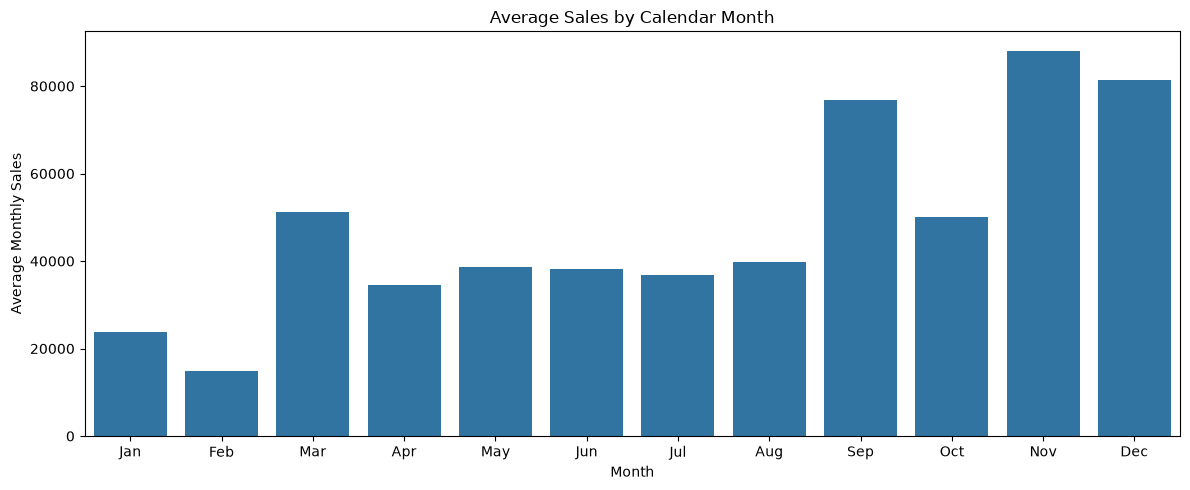

In [32]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=seasonality_analysis.reset_index(),
    x="month",
    y="average_sales"
)

plt.title("Average Sales by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Monthly Sales")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/08_average_monthly_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

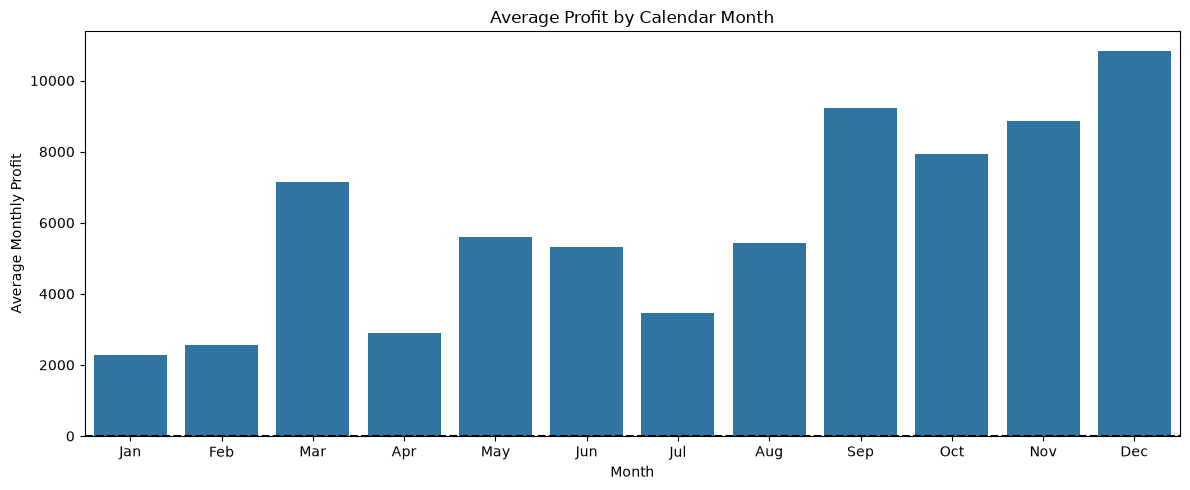

In [33]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=seasonality_analysis.reset_index(),
    x="month",
    y="average_profit"
)

plt.title("Average Profit by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Monthly Profit")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.axhline(y=0, color="black", linestyle="--")

plt.tight_layout()

plt.savefig(
    "../reports/figures/09_average_monthly_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 15. Monthly Sales Comparison by Year

Compare monthly sales across individual years
to investigate whether seasonal patterns
are consistent over time.

In [34]:
# Extract year and month

monthly_analysis["year"] = (
    monthly_analysis["Order Date"].dt.year
)

monthly_analysis["month_number"] = (
    monthly_analysis["Order Date"].dt.month
)

# Create month-by-year comparison

sales_month_year = monthly_analysis.pivot(
    index="month_number",
    columns="year",
    values="total_sales"
)

display(sales_month_year.round(2))

year,2014,2015,2016,2017
month_number,,,,
1,14236.90,18174.08,18542.49,43971.37
2,4519.89,11951.41,22978.82,20301.13
3,55691.01,38726.25,51715.88,58872.35
4,28295.34,34195.21,38750.04,36521.54
5,23648.29,30131.69,56987.73,44261.11
6,34595.13,24797.29,40344.53,52981.73
7,33946.39,28765.32,39261.96,45264.42
8,27909.47,36898.33,31115.37,63120.89
9,81777.35,64595.92,73410.02,87866.65


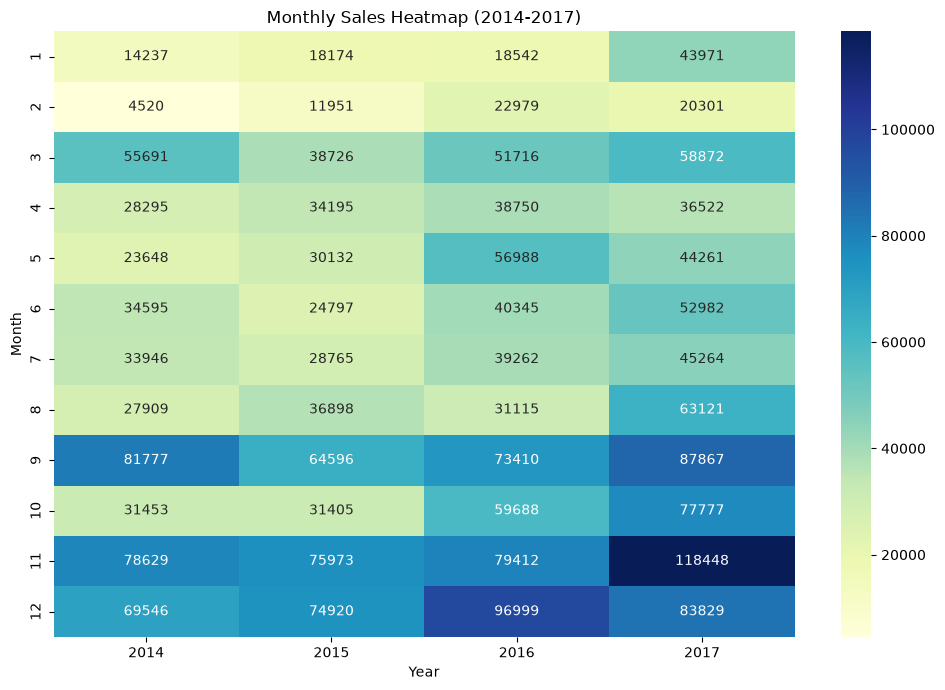

In [35]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    sales_month_year,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Monthly Sales Heatmap (2014-2017)")
plt.xlabel("Year")
plt.ylabel("Month")

plt.tight_layout()

plt.savefig(
    "../reports/figures/10_monthly_sales_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings - Monthly Sales Seasonality

The monthly sales heatmap reveals several patterns:

1. Sales tend to increase during September to December.
2. November and December frequently record the
   highest monthly sales.
3. February consistently shows relatively low
   sales across the four-year observation period.
4. The highest-selling month varies across years.

These observations suggest a possible seasonal
pattern in retail sales.

However, additional historical data and business
context would be needed to validate the seasonal
effect and identify its underlying causes.

# 16. Business Insights & Recommendations

## A. Key Business Insights

### 1. Product Performance

- Technology generated the highest total sales
  ($836,154.03) and total profit ($145,454.95),
  with a profit margin of 17.40%.
- Furniture generated substantial sales
  ($741,999.80), but its profit margin was only 2.49%.
- Tables and Bookcases were the main loss-making
  sub-categories within Furniture.
- Machines remained profitable overall, despite
  several individual products generating significant losses.

### 2. Regional Performance

- West recorded the highest sales, profit,
  and profit margin.
- Central had the lowest regional profit margin
  at 7.92%.
- Furniture was the only loss-making category
  in Central, with a total loss of $2,871.05.
- Central Furnishings showed particularly weak
  profitability, with a profit margin of -25.61%.

### 3. Discount and Profitability

- Central Furnishings recorded a total profit
  of $2,038.44 at a 0.0 discount level.
- At a 0.6 discount level, the same sub-category
  recorded a total loss of $5,944.66.
- All 138 records at the 0.6 discount level
  generated negative profit.

This indicates a strong association between
high discount levels and negative profitability
within Central Furnishings.

### 4. Customer Segment

- Consumer generated the highest total sales
  and total profit.
- Home Office had the highest profit margin
  at 14.03%.
- Home Office also generated the highest
  average profit per customer.

### 5. Sales Trends and Seasonality

- Annual sales increased substantially in 2016
  and 2017.
- Annual profit increased consistently from
  2014 to 2017.
- Average discount remained relatively stable.
- Monthly sales tended to be higher during
  September to December.
- February consistently recorded relatively
  low monthly sales across the observed years.

## B. Business Recommendations

### 1. Review Furniture Profitability

Investigate Tables and Bookcases, especially
products with consistently negative profits.

Review pricing, discount strategies, and
product-level performance before making
decisions about product availability.

### 2. Evaluate Central Region Performance

Prioritize an investigation into Central Furniture,
particularly the Furnishings sub-category.

Review the product mix and discount structure
to identify opportunities for improvement.

### 3. Review Discount Policies

Evaluate the profitability impact of high discounts,
particularly within Central Furnishings.

Avoid applying high discounts without considering
product-level profitability.

### 4. Develop Customer Segment Strategies

Maintain the Consumer segment as an important
sales contributor while exploring opportunities
to improve its profit margin.

Consider strategies to strengthen the
Home Office segment based on its higher
average profit per customer.

### 5. Improve Seasonal Planning

Use the observed September-December sales
patterns to support inventory and sales planning.

Monitor monthly performance to evaluate
whether these patterns continue in future periods.

## C. Analysis Limitations

- The dataset covers the period from 2014 to 2017.
- The analysis is based on observational sales data.
- Relationships between discounts and profitability
  do not establish direct causation.
- Detailed operational costs and marketing campaign
  information are not available in the dataset.
- Further investigation is required before
  implementing business recommendations.

## D. Overall Conclusion

The analysis shows that strong overall sales
do not necessarily indicate strong profitability.

Technology demonstrates the strongest overall
financial performance, while Furniture requires
further attention due to several loss-making
sub-categories.

Regional differences, discount levels, and
customer segments also reveal opportunities
for more targeted business strategies.

This project demonstrates the use of Python,
Pandas, and data visualization to explore,
interpret, and communicate retail business data.